# Predicción de demoras en envíos

En este trabajo se utilizarán dos modelos de clasificación,
Árbol de Decisión y Support Vector Machine (SVM), para predecir
si un producto comprado mediante comercio electrónico llegará
a tiempo o tendrá una demora.

Luego se compararán los resultados obtenidos para determinar
cuál de los dos modelos aborda mejor el problema.

In [1]:
import pandas as pd

envios = pd.read_csv("/content/Train.csv")

envios.head()

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


In [2]:
envios.shape
envios.info()
envios.isnull().sum()
envios["Reached.on.Time_Y.N"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   10999 non-null  int64 
 1   Warehouse_block      10999 non-null  object
 2   Mode_of_Shipment     10999 non-null  object
 3   Customer_care_calls  10999 non-null  int64 
 4   Customer_rating      10999 non-null  int64 
 5   Cost_of_the_Product  10999 non-null  int64 
 6   Prior_purchases      10999 non-null  int64 
 7   Product_importance   10999 non-null  object
 8   Gender               10999 non-null  object
 9   Discount_offered     10999 non-null  int64 
 10  Weight_in_gms        10999 non-null  int64 
 11  Reached.on.Time_Y.N  10999 non-null  int64 
dtypes: int64(8), object(4)
memory usage: 1.0+ MB


,count
Reached.on.Time_Y.N,
1,6563
0,4436


In [8]:
X = envios.drop(
    columns=[
        "ID",
        "Reached.on.Time_Y.N"
    ]
)

y = envios["Reached.on.Time_Y.N"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (10999, 10)
Dimensiones de y: (10999,)


In [7]:
variables_categoricas = [
    "Warehouse_block",
    "Mode_of_Shipment",
    "Product_importance",
    "Gender"
]

X_codificado = pd.get_dummies(
    X,
    columns=variables_categoricas,
    drop_first=True,
    dtype=int
)

print(
    "Dimensiones después del one-hot:",
    X_codificado.shape
)


Dimensiones después del one-hot: (10999, 15)


In [11]:
from sklearn.model_selection import train_test_split

X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X_codificado,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", X_entrenamiento.shape)

print("Datos de prueba:", X_prueba.shape)

Datos de entrenamiento: (8799, 15)
Datos de prueba: (2200, 15)


In [12]:
from sklearn.tree import DecisionTreeClassifier

modelo_arbol = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)
modelo_arbol.fit(
    X_entrenamiento,
    y_entrenamiento
)
predicciones_arbol = modelo_arbol.predict(
    X_prueba
)

In [13]:
exactitud_arbol = modelo_arbol.score(
    X_prueba,
    y_prueba
)

print(
    "Exactitud del Árbol de Decisión:",
    round(exactitud_arbol * 100, 2),
    "%"
)

Exactitud del Árbol de Decisión: 67.41 %


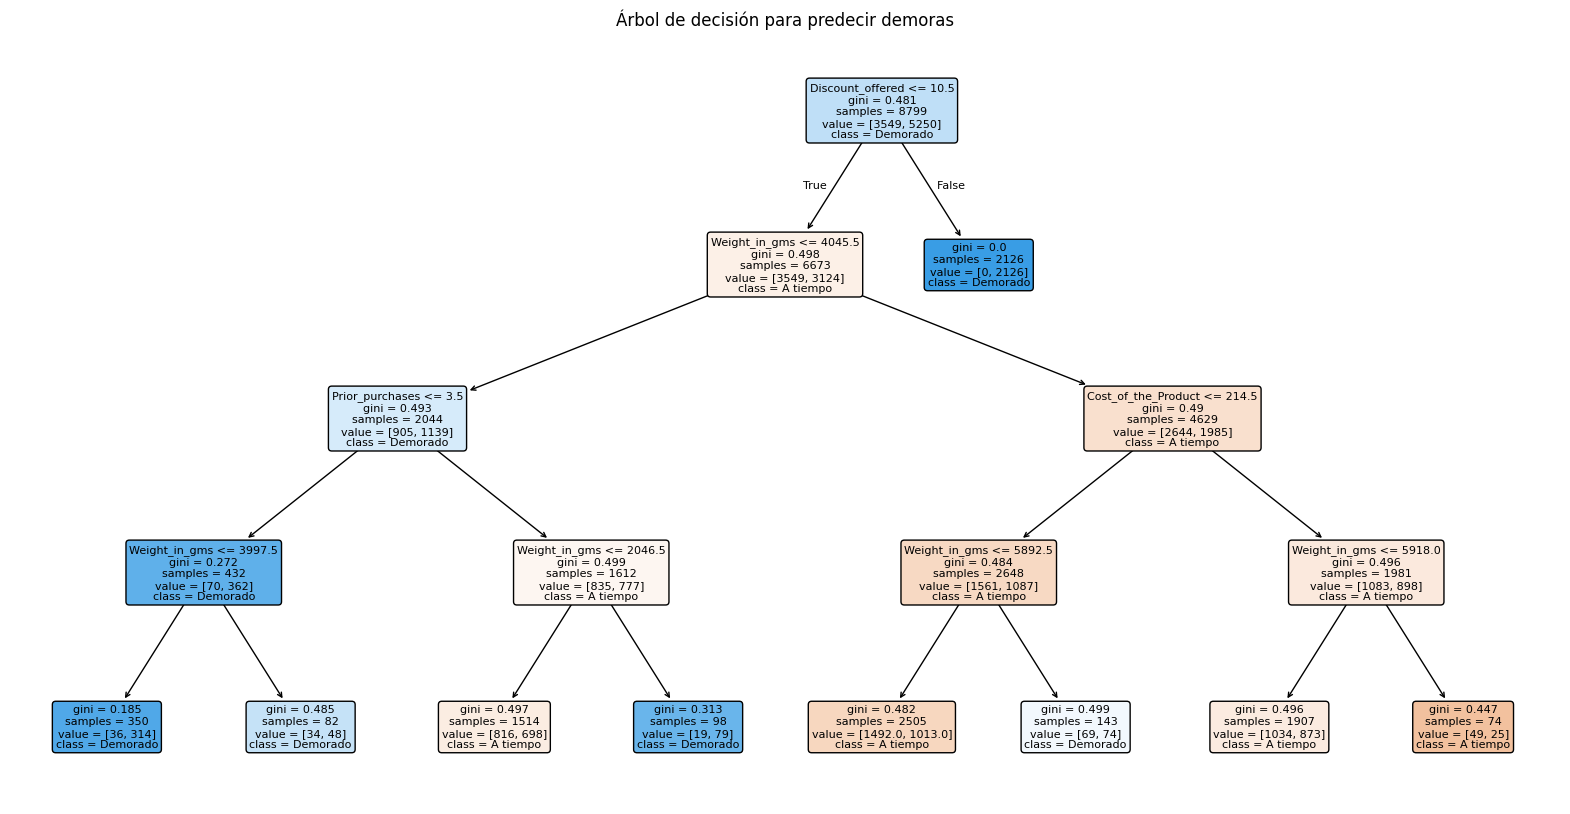

In [14]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    modelo_arbol,
    feature_names=X_entrenamiento.columns,
    class_names=["A tiempo", "Demorado"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Árbol de decisión para predecir demoras")
plt.show()

El árbol de decisión utiliza principalmente el descuento ofrecido, el peso del producto, las compras anteriores y el costo del producto para clasificar los envíos. La primera división se realiza según el descuento, lo que indica que esta variable tiene una influencia importante en la predicción.

# Escalado de los datos para SVM

Antes de entrenar el modelo SVM, se estandarizan las variables para que todas tengan una escala comparable.

In [15]:
from sklearn.preprocessing import StandardScaler

escalador = StandardScaler()

X_entrenamiento_escalado = escalador.fit_transform(X_entrenamiento)

X_prueba_escalado = escalador.transform(X_prueba)

# Modelo Support Vector Machine (SVM)
Se entrena un modelo SVM utilizando los datos estandarizados para predecir si los envíos llegan a tiempo o con demora.

In [16]:
from sklearn.svm import SVC

modelo_svm = SVC()

modelo_svm.fit(
    X_entrenamiento_escalado,
    y_entrenamiento
)

predicciones_svm = modelo_svm.predict(
    X_prueba_escalado
)

exactitud_svm = modelo_svm.score(
    X_prueba_escalado,
    y_prueba
)

print(
    "Exactitud del modelo SVM:",
    round(exactitud_svm * 100, 2),
    "%"
)

Exactitud del modelo SVM: 64.91 %


#Comparación de los modelos
Se comparan las exactitudes obtenidas por el árbol de decisión y el modelo SVM sobre el mismo conjunto de prueba.

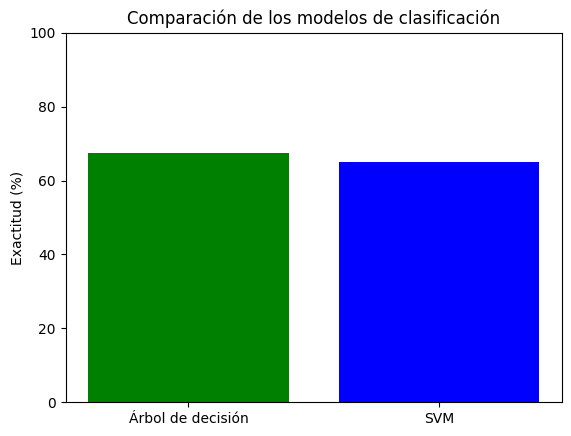

In [17]:
import matplotlib.pyplot as plt

modelos = ["Árbol de decisión", "SVM"]
exactitudes = [exactitud_arbol * 100, exactitud_svm * 100]

plt.bar(modelos, exactitudes, color=["green", "blue"])

plt.ylabel("Exactitud (%)")
plt.title("Comparación de los modelos de clasificación")
plt.ylim(0, 100)

plt.show()

#Conclusión
En este trabajo se utilizaron un Árbol de Decisión y un modelo SVM para predecir si un envío llegaría a tiempo o con demora.

El Árbol de Decisión obtuvo una exactitud del 67,41 %, mientras que el modelo SVM alcanzó un 64,91 %. Ambos modelos fueron evaluados con el mismo conjunto de prueba, por lo que la comparación se realizó sobre las mismas observaciones.
En este caso, considero que el Árbol de Decisión aborda mejor el problema, ya que obtuvo una exactitud mayor y además permite visualizar las decisiones tomadas. Se observó que variables como el descuento ofrecido, el peso, las compras anteriores y el costo del producto fueron utilizadas para clasificar los envíos.

El modelo SVM también logró realizar predicciones, pero necesitó que los datos fueran escalados y su resultado fue ligeramente inferior. De todas formas, los resultados podrían mejorarse probando otras configuraciones de los modelos.